##Install libraries

In [ ]:
!pip install pysindy==1.7.5 numpy==1.26.4 scipy==1.13.1 scikit-learn==1.5.2
!pip install iisignature

  Using cached iisignature-0.24.tar.gz (1.3 MB)
  Preparing metadata (setup.py) ... done
  Created wheel for iisignature: filename=iisignature-0.24-cp312-cp312-linux_x86_64.whl size=3247898 sha256=73ac4b9b6b079aed4b6f988c1689260e0317ab07204ab54944a98d4f092ac654
  Stored in directory: /root/.cache/pip/wheels/7d/b3/8c/168fb7d3b31255a501dea7fa1f5e5098e63ec61a786eeb0156
Successfully built iisignature


##Import libraries

In [ ]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pysindy as ps
import random
import iisignature
from sklearn import linear_model
from sklearn.metrics import mean_squared_error
from tqdm import tqdm
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit

##Defining parameters and simulating noise

In [ ]:
N = 100000
T = 1.0
t = np.linspace(0, T, N)
dt = T / N

np.random.seed(3)
dW = np.sqrt(dt) * np.random.randn(N)
W_ = np.cumsum(dW)


r = 0.5
sigm = 0.3
S0 = 1.0
kappa = 0.5
theta = 0
w1 = -1
w2 = 0.5
w3 = 1.0
w4 = 0.25
K = 0.1
beta = 0.2

##Simulating primary processes

## $$dS_t = \mu(S_t)dt + \sigma(S_t)dB_t$$

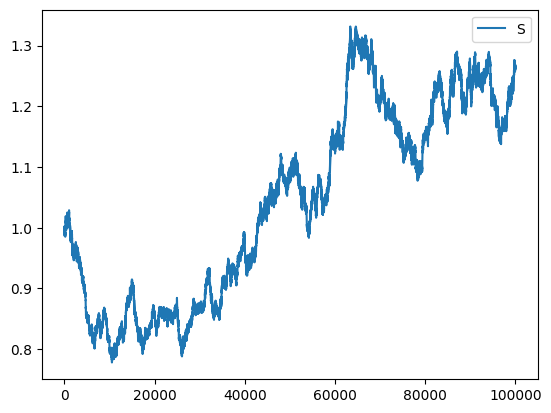

In [ ]:
drift =  "BS"
diff = "BS"
#Change to "BS" for Black-Scholes Model
def mu(x,drift):
  if drift == "constant":
    return r*np.ones_like(x)
  if drift == "BS":
    return r*x
  if drift == "quadratic":
    return r*x**2
  if drift == "quadratic1":
    return  0.3*x**2 + 0.7*x
  if drift == "quadratic2":
    return  0.25*x*(1.0-x*x)
  if drift == "sin":
    return r*np.sin(x)
  if drift == "OU":
    return kappa * (theta - x)
  if drift == "Double_well_potential":
    return w1*x**3 + w2*x
  if drift == "population":
    return r*x*(K + x)

def sigma(x,diff):
  if diff == "OU":
    return sigm*np.ones_like(x)
  if diff == "BS":
    return sigm*x
  if diff == "quadratic":
    return sigm*x**2
  if diff == "quadratic1":
    return   0.1*x**2 + 0.5*x
  if diff == "quadratic2":
    return   -0.5*(1.0-x**2)
  if diff == "Double_well_potential":
    return w3 + w4*x**2
  if diff == "population":
    return beta*x

S_ = np.zeros(N)
S_[0]=S0
for i in range(N-1):
  S_[i+1] = S_[i] + mu(S_[i],drift) * dt + (sigma(S_[i],diff)) * dW[i]

mu_exact_ = mu(S_,drift)
sigma_exact_ = sigma(S_,diff)

plt.plot(S_, label="S")
plt.legend()
plt.show()

##compute quadratic variation

100%|██████████| 100000/100000 [00:09<00:00, 10419.02it/s]


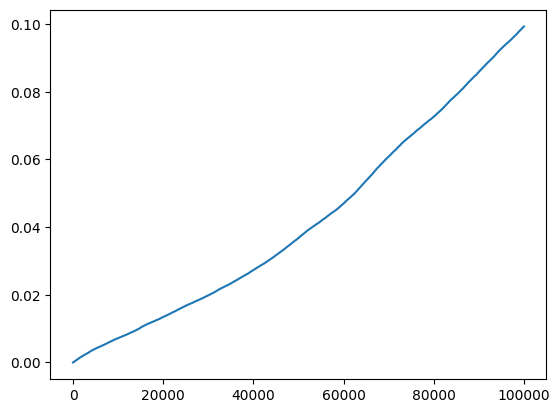

In [ ]:
def compute_quadratic_variation(W):
    return np.sum(np.diff(W) ** 2)
QVS = np.zeros(N)
for i in tqdm(range(N)):
  QVS[i] = compute_quadratic_variation(S_[0:i])
QV = QVS.copy()
diff_method = ps.FiniteDifference(order=3)
dQV = diff_method._differentiate(QV.reshape(-1, 1), t).flatten()
plt.plot(QV)

##Approximating $\sigma$

In [ ]:
model = ps.SINDy(
    optimizer=ps.SR3(
        threshold=5.0,          # for BS try 3.6
        nu=2.2,                  # for BS try 0.2
        thresholder='l1',
        normalize_columns=True,
        fit_intercept=False,
        max_iter=1500,
        tol=1e-12                # for BS try 1e-1
    ),
    feature_library=ps.PolynomialLibrary(degree=4, include_interaction=True, include_bias=True)
)

model.fit(S_.reshape(-1, 1), t, x_dot=dQV.reshape(-1, 1))
print(model.equations())

['0.091 x0^2 + -0.002 x0^3']


/usr/local/lib/python3.12/dist-packages/pysindy/optimizers/sr3.py:390: ConvergenceWarning: SR3._reduce did not converge after 1500 iterations.
  warnings.warn(


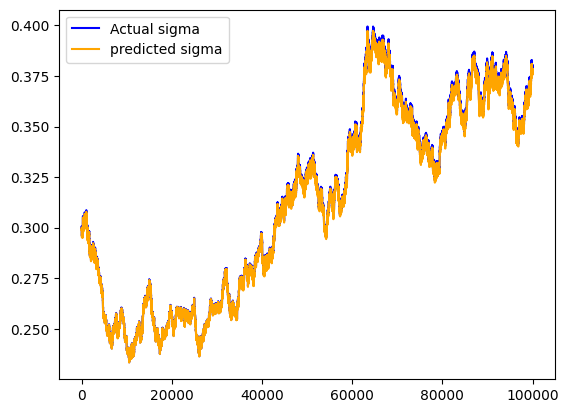

In [ ]:
sigma_pred_ = np.sqrt(model.predict(S_.reshape(-1, 1)))
sigma_pred_ = np.array(sigma_pred_)
plt.plot(sigma_exact_, label="Actual sigma",color="blue")
plt.plot(sigma_pred_,label="predicted sigma", color="orange")
plt.legend()
plt.show()

In [ ]:
sigma_prime_ = diff_method._differentiate(sigma_pred_.reshape(-1, 1), S_).flatten()
sigma_2prime_ = diff_method._differentiate(sigma_prime_.reshape(-1, 1), S_).flatten()
sigma_3prime_ = diff_method._differentiate(sigma_2prime_.reshape(-1, 1), S_).flatten()

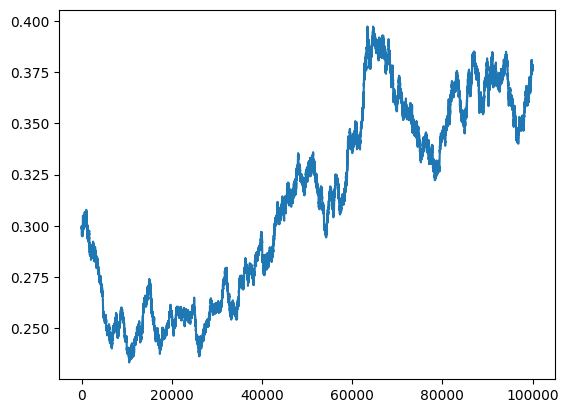

In [ ]:
plt.plot(sigma_pred_)

##Q Brownian motion

/tmp/ipython-input-2667744426.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  BQ_[i] = BQ_[i-1] + (S_[i] - S_[i-1])/sigma_pred_[i-1]


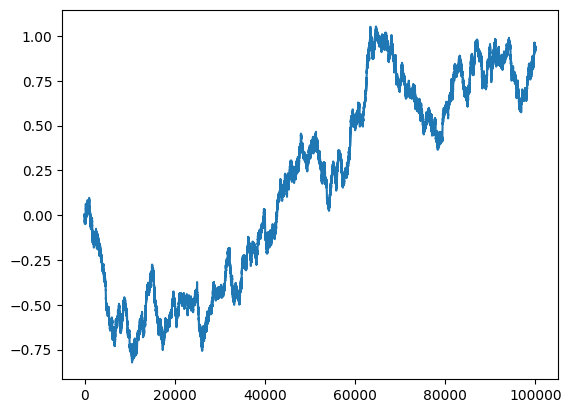

In [ ]:
BQ_ = np.zeros(len(S_))
for i in range(1,len(S_)):
  BQ_[i] = BQ_[i-1] + (S_[i] - S_[i-1])/sigma_pred_[i-1]
plt.plot(BQ_)

#Fit signature model

In [ ]:
keep_cols = [0, 1, 3, 4, 5, 13]

100%|██████████| 1000/1000 [00:02<00:00, 389.70it/s]


3.5290749186742215e-05

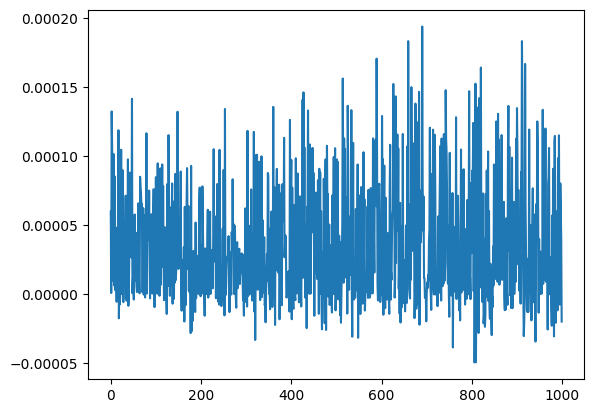

In [ ]:
M = 100
K = int(N/M)
l21 = []
for i in tqdm(range(K)):
  path = np.array([[t[k], BQ_[k]] for k in range(i*M,i*M+M)])
  X1 = np.array([iisignature.sig(path[0:i], 3) for i in range(1,len(path)+1)])
  X1_reduced = X1[:, keep_cols]
  clf = linear_model.Ridge(alpha=0.01)
  clf.fit(X1_reduced, S_[i*M:i*M+M])
  l21.append(clf.coef_[3])
l21 = np.array(l21)
plt.plot(l21)
np.mean(l21)

In [ ]:
sigma_pred = np.zeros(K)
mu_exact = np.zeros(K)
S = np.zeros(K)
BQ = np.zeros(K)
W = np.zeros(K)
sigma_exact = np.zeros(K)
for i in range(K):
  sigma_pred[i] = sigma_pred_[i*M]
  S[i] = S_[i*M]
  mu_exact[i] = mu_exact_[i*M]
  BQ[i] = BQ_[i*M]
  W[i] = W_[i*M]
  sigma_exact[i] = sigma_exact_[i*M]

/tmp/ipython-input-1445465880.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sigma_pred[i] = sigma_pred_[i*M]


In [ ]:
sigma_prime = diff_method._differentiate(sigma_pred.reshape(-1, 1), S).flatten()
sigma_2prime = diff_method._differentiate(sigma_prime.reshape(-1, 1), S).flatten()
sigma_3prime = diff_method._differentiate(sigma_2prime.reshape(-1, 1), S).flatten()

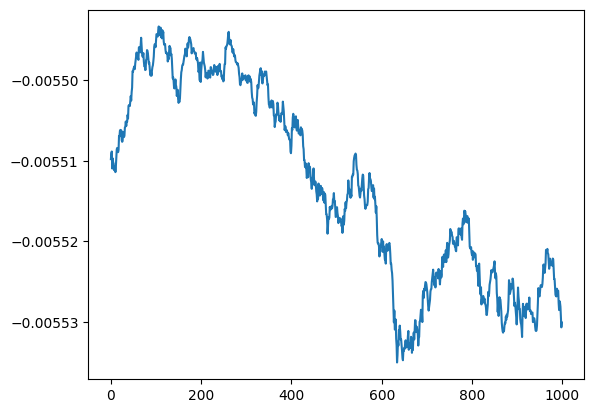

In [ ]:
plt.plot(sigma_2prime)

## Predicting $\mu(X_t)$ by tuncating up to level-2 of iterated integrals

In [ ]:
mu_0 = mu_exact[0]
#a  = sigma_prime/sigma_pred.squeeze()
#b  = (2*l21 + sigma_pred.squeeze()*sigma_prime**2 + sigma_pred.squeeze()**2*sigma_2prime)/(2*sigma_pred.squeeze())
#G = mu_prime*sigma_pred - mu_exact*sigma_prime - 0.5*(sigma_pred*sigma_prime**2 + sigma_pred**2*sigma_2prime)

a  = sigma_prime/sigma_pred
b  = l21/sigma_pred + 0.5*(sigma_prime**2 + sigma_pred*sigma_2prime)
G = - 0.5*(sigma_pred*sigma_prime**2 + sigma_pred**2*sigma_2prime)
b_  = G/sigma_pred + 0.5*(sigma_prime**2 + sigma_pred*sigma_2prime)

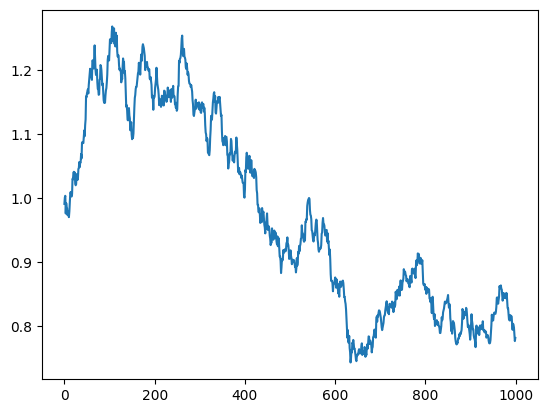

In [ ]:
#plt.plot(b)
plt.plot(a)

In [ ]:
mu_pred1 = np.zeros(K)
mu_pred2 = np.zeros(K)
mu_pred1[0] = mu_0
mu_pred2[0] = mu_0
for i in range(1,len(a)):
  mu_pred1[i] = mu_pred1[i-1] + (a[i-1]*mu_pred1[i-1]+ b[i-1])*(S[i] - S[i-1])
  mu_pred2[i] = mu_pred2[i-1] + (a[i-1]*mu_pred2[i-1]+ b_[i-1])*(S[i] - S[i-1])
mu_pred2 = np.round(mu_pred2,8)

<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipython-input-2429398061.py:7: SyntaxWarning: invalid escape sequence '\m'
  axes[0].set_ylabel("$\mu(X_t)$")
/tmp/ipython-input-2429398061.py:13: SyntaxWarning: invalid escape sequence '\m'
  axes[1].set_ylabel("$\mu(X_t)$")


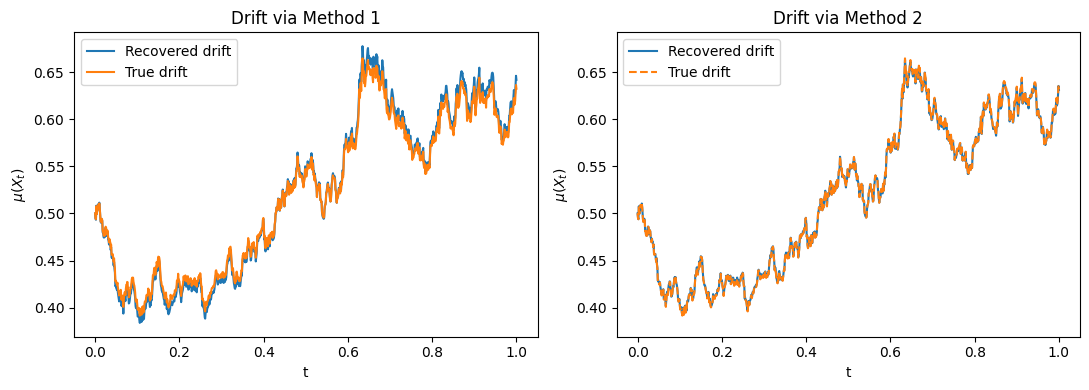

In [ ]:
t_ = np.linspace(0, T, K)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t_, mu_pred1, label="Recovered drift")
axes[0].plot(t_, mu_exact, label="True drift")
axes[0].set_title("Drift via Method 1")
axes[0].set_xlabel("t")
axes[0].set_ylabel("$\mu(X_t)$")
axes[0].legend()
axes[1].plot(t_, mu_pred2, label="Recovered drift")
axes[1].set_title("Drift via Method 2")
axes[1].plot(t_, mu_exact, '--', label="True drift")
axes[1].set_xlabel("t")
axes[1].set_ylabel("$\mu(X_t)$")
axes[1].legend()
axes[1].set_ylim(axes[0].get_ylim())

plt.tight_layout()
plt.savefig("Drift_via_Euler_BS.png", bbox_inches='tight', dpi=300)
plt.show()

##Predicting P-Brownian motion

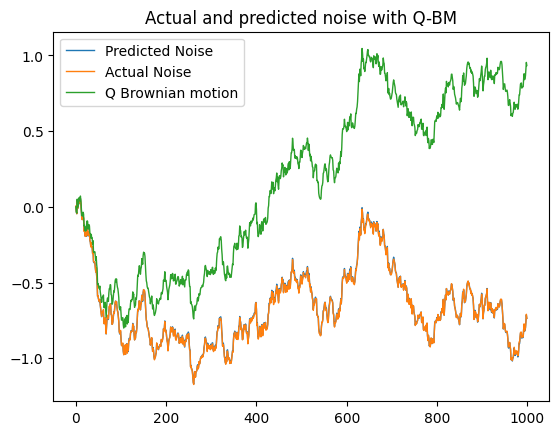

In [ ]:
model = "Psi_approx_BS"
#model = "Psi_true_BS"
BP = np.zeros(K)
dt = T/K
t = np.linspace(0, T, K)
for i in range(1,K):
  BP[i] = BP[i-1] + BQ[i] - BQ[i-1] -  (mu_pred1[i-1]/sigma_pred[i-1])*dt
plt.plot(BP, label="Predicted Noise", linewidth=1)
plt.plot(W, label="Actual Noise", linewidth=1)
plt.plot(BQ, label="Q Brownian motion", linewidth=1)
plt.title("Actual and predicted noise with Q-BM")
plt.legend()
plt.savefig(f"{model}_Actual and predicted noise with Q-BM.png", bbox_inches='tight', dpi=300)
plt.show()

MSE: 5.244e-09
μ(X) = 0.503773*X
σ(X) = 0.00323797 + 0.295761*X
[CV best] alpha=0.000387, l1_ratio (rho)=0.85


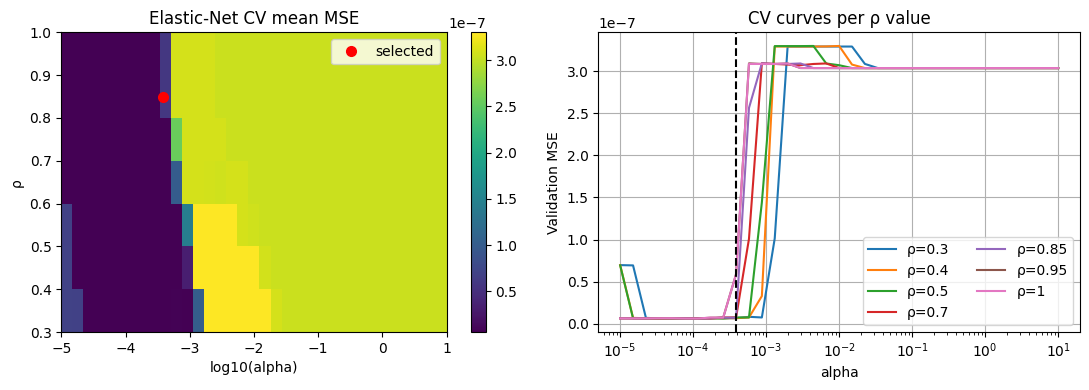

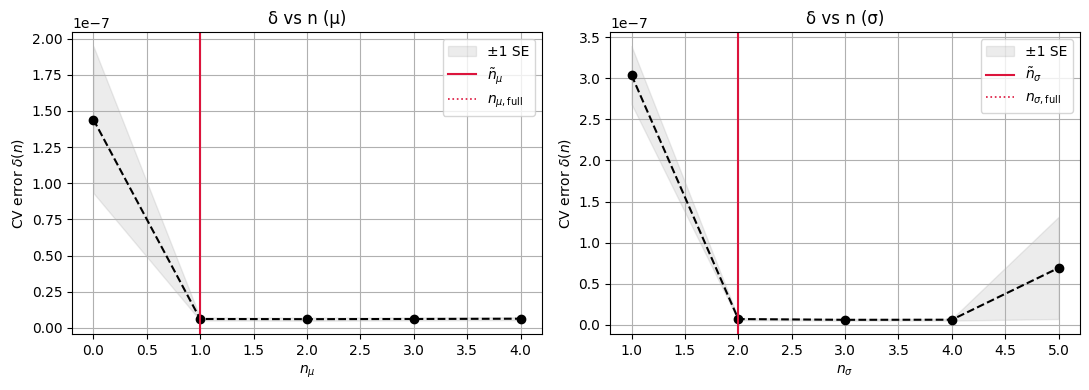

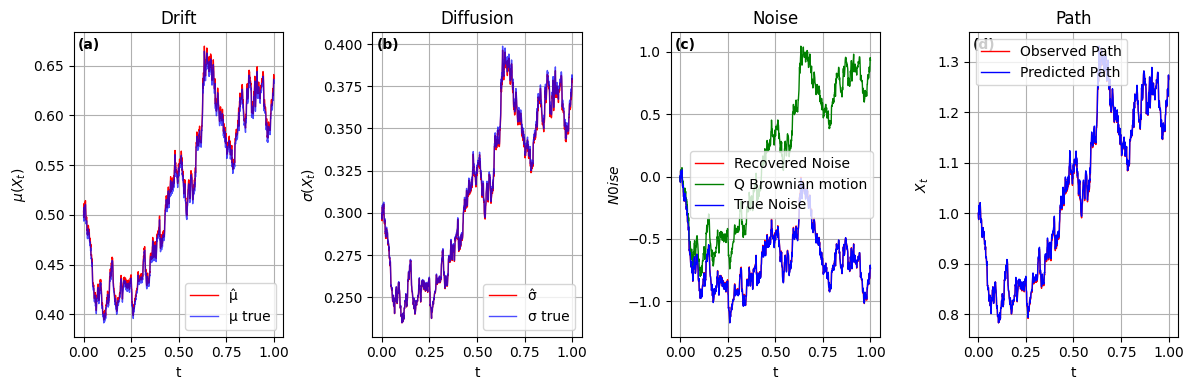

In [ ]:
class StochSINDy:
    def __init__(self,
                 mu_deg=5, si_deg=5,          # poly degrees for μ and σ
                 pen="elasticnet",            # "lasso" | "elasticnet" | "ridge"
                 use_cv=True,                 # run TimeSeriesSplit CV?
                 k=5,                         # folds
                 alphas=None,                 # λ grid
                 rhos=None,                   # ρ grid (ElasticNet only)
                 use_1se=True,                # 1-SE rule?
                 thr1=5e-3, thr2=7e-3):       # ridge-only thresholds
        self.mu_deg = mu_deg
        self.si_deg = si_deg
        self.pen = pen.lower()
        self.use_cv = use_cv
        self.k = k
        self.use_1se = use_1se
        self.thr1, self.thr2 = thr1, thr2

        # default grids
        self.alphas = np.logspace(-4, 0, 12) if alphas is None else np.asarray(alphas, float)
        self.rhos   = np.array([0.3, 0.5, 0.7, 0.9]) if rhos is None else np.asarray(rhos, float)

        # learned stuff
        self.mu_c = None       # μ coeffs
        self.si_c = None       # σ coeffs
        self.dt = None
        self.mse = None

        # keep scales
        self._s_mu = None
        self._s_si = None
        self._g_mu = None
        self._g_si = None

        # best hyperparams + CV cache (for plots)
        self.best_a = None     # alpha
        self.best_r = None     # l1_ratio
        self.cv = None         # dict with arrays for plotting

    def _poly(self, x, deg, bias=True):
        """[1, x, x^2, ...] up to 'deg'."""
        x = np.asarray(x).reshape(-1)
        cols = [np.ones_like(x)] if bias else []
        cols += [x**d for d in range(1, deg + 1)]
        return np.column_stack(cols)

    def _rms_norm(self, Z, eps=1e-12):
        """Column RMS normalize."""
        s = np.sqrt(np.mean(Z**2, axis=0))
        s[s < eps] = 1.0
        return Z / s, s

    def _make_blocks(self, Xmid, dBP, dt):
        """Design blocks for μ and σ."""
        Th_mu = self._poly(Xmid, self.mu_deg, bias=True)
        Th_si = self._poly(Xmid, self.si_deg, bias=True)
        Zm = dt * Th_mu                 # μ block
        Zs = dBP[:, None] * Th_si       # σ block
        return Th_mu, Th_si, Zm, Zs

    def _norm_by_train(self, Zm, Zs, tr_idx):
        """Normalize using train-only stats; apply to all rows (no leakage)."""
        Zm_tr, Zs_tr = Zm[tr_idx], Zs[tr_idx]
        Zm_trn, s_mu = self._rms_norm(Zm_tr)
        Zs_trn, s_si = self._rms_norm(Zs_tr)
        g_mu = float(np.sqrt(np.mean(Zm_trn**2))) or 1.0
        g_si = float(np.sqrt(np.mean(Zs_trn**2))) or 1.0
        Zm_all = (Zm / s_mu) / g_mu
        Zs_all = (Zs / s_si) / g_si
        return Zm_all, Zs_all, s_mu, s_si, g_mu, g_si

    def _ols_on(self, Z, y, mask):
        """OLS on active columns; returns full-length coef with zeros elsewhere."""
        if not mask.any():
            mask[np.argmax(np.abs(Z.T @ y))] = True
        Za = Z[:, mask]
        beta_a, *_ = np.linalg.lstsq(Za, y, rcond=None)
        beta = np.zeros(Z.shape[1]); beta[mask] = beta_a
        return beta

    def _fmt_poly(self, c, bias=True, tol=5e-12):
        """Readable polynomial string."""
        terms = []
        start = 0 if bias else 1
        for i, v in enumerate(c):
            if abs(v) < tol: continue
            p = i + start
            if   p == 0: terms.append(f"{v:.6g}")
            elif p == 1: terms.append(f"{v:.6g}*X")
            else:        terms.append(f"{v:.6g}*X^{p}")
        return " + ".join(terms) if terms else "0"

    # ------------------- fit -------------------
    def fit(self, X, BP, dt, alpha_mu=1e-3, alpha_si=1e-2):
        self.dt = float(dt)
        X = np.asarray(X).ravel()
        BP = np.asarray(BP).ravel()
        dX = np.diff(X)
        dBP = np.diff(BP)
        Xmid = X[:-1]

        Th_mu, Th_si, Zm_raw, Zs_raw = self._make_blocks(Xmid, dBP, self.dt)
        n_mu, n_si = Th_mu.shape[1], Th_si.shape[1]

        # ----- ridge branch (kept minimal) -----
        if self.pen == "ridge":
            Zm_n, s_mu = self._rms_norm(Zm_raw)
            Zs_n, s_si = self._rms_norm(Zs_raw)
            g_mu = float(np.sqrt(np.mean(Zm_n**2))) or 1.0
            g_si = float(np.sqrt(np.mean(Zs_n**2))) or 1.0
            Z = np.c_[Zm_n / g_mu, Zs_n / g_si]
            ZTZ, ZTy = Z.T @ Z, Z.T @ dX
            R = np.zeros_like(ZTZ)
            R[:n_mu, :n_mu] = alpha_mu * np.eye(n_mu)
            R[n_mu:, n_mu:] = alpha_si * np.eye(n_si)
            b = np.linalg.solve(ZTZ + R, ZTy)
            # two rounds of hard threshold + refit
            b = self._ols_on(Z, dX, np.abs(b) >= self.thr1)
            b = self._ols_on(Z, dX, np.abs(b) >= self.thr2)
            # unscale back
            b[:n_mu] /= g_mu; b[n_mu:] /= g_si
            self.mu_c = b[:n_mu] / s_mu
            self.si_c = b[n_mu:] / s_si
            self.cv = None

        # ----- L1 / EN branch with CV + 1-SE -----
        else:
            # run CV if asked; otherwise use the first (alpha, rho)
            if self.use_cv:
                tscv = TimeSeriesSplit(n_splits=self.k)
                grid = [(float(a), None) for a in self.alphas] if self.pen == "lasso" else \
                       [(float(a), float(r)) for a in self.alphas for r in self.rhos]
                E = {g: [] for g in grid}          # MSE per fold
                S_mu = {g: [] for g in grid}       # μ support per fold
                S_si = {g: [] for g in grid}       # σ support per fold

                for tr, va in tscv.split(dX):
                    Zm, Zs, smu, ssi, gmu, gsi = self._norm_by_train(Zm_raw, Zs_raw, tr)
                    Ztr = np.c_[Zm[tr], Zs[tr]]
                    Zva = np.c_[Zm[va], Zs[va]]
                    ytr, yva = dX[tr], dX[va]

                    for a, r in grid:
                        mdl = (Lasso(alpha=a, fit_intercept=False, max_iter=20000) if self.pen=="lasso"
                               else ElasticNet(alpha=a, l1_ratio=r, fit_intercept=False, max_iter=20000))
                        mdl.fit(Ztr, ytr)
                        beta = mdl.coef_.copy()
                        # debias: OLS on active
                        act = np.abs(beta) > 0
                        beta_ref = self._ols_on(Ztr, ytr, act)
                        # val error
                        yhat = Zva @ beta_ref
                        E[(a, r)].append(np.mean((yva - yhat)**2))
                        # support split
                        S_mu[(a, r)].append(int(act[:n_mu].sum()))
                        S_si[(a, r)].append(int(act[n_mu:].sum()))

                keys = list(E.keys())
                mean = np.array([np.mean(E[k]) for k in keys])
                se   = np.array([np.std(E[k], ddof=1)/np.sqrt(self.k) for k in keys])
                s_mu = np.array([np.mean(S_mu[k]) for k in keys])
                s_si = np.array([np.mean(S_si[k]) for k in keys])

                jmin = int(np.argmin(mean))
                thr = mean[jmin] + (se[jmin] if self.use_1se else 0.0)

                # tie-breaker: pick simpler (bigger alpha, then bigger rho)
                feas = [j for j in range(len(keys)) if mean[j] <= thr]
                def simp(j):
                    a, r = keys[j]; r = 1.0 if r is None else r
                    return (a, r)
                jsel = max(feas, key=simp) if feas else jmin
                self.best_a, self.best_r = keys[jsel]

                # stash minimal CV data for plots
                if self.pen == "lasso":
                    A = np.array([k[0] for k in keys]); ordA = np.argsort(A)
                    self.cv = dict(kind="lasso", A=A[ordA],
                                   mean=mean[ordA], se=se[ordA],
                                   nmu=s_mu[ordA], nsi=s_si[ordA],
                                   a_sel=self.best_a, r_sel=None,
                                   use_1se=self.use_1se)
                else:
                    A = np.unique([k[0] for k in keys]); A.sort()
                    R = np.unique([k[1] for k in keys]); R.sort()
                    M = np.full((len(R), len(A)), np.nan)
                    S = np.full_like(M, np.nan)
                    Nmu = np.full_like(M, np.nan)
                    Nsi = np.full_like(M, np.nan)
                    for idx, (k, m, s) in enumerate(zip(keys, mean, se)):
                        j = np.where(np.isclose(A, k[0]))[0][0]
                        i = np.where(np.isclose(R, k[1]))[0][0]
                        M[i, j] = m; S[i, j] = s; Nmu[i, j] = s_mu[idx]; Nsi[i, j] = s_si[idx]
                    self.cv = dict(kind="enet", A=A, R=R, mean=M, se=S, nmu=Nmu, nsi=Nsi,
                                   a_sel=self.best_a, r_sel=self.best_r, use_1se=self.use_1se)
            else:
                # no CV: just take first grid point
                self.best_a = float(np.atleast_1d(self.alphas)[0])
                self.best_r = None if self.pen == "lasso" else float(np.atleast_1d(self.rhos)[0])
                self.cv = None

            # retrain on ALL data with full-data normalization
            Zm_n, smu = self._rms_norm(Zm_raw)
            Zs_n, ssi = self._rms_norm(Zs_raw)
            gmu = float(np.sqrt(np.mean(Zm_n**2))) or 1.0
            gsi = float(np.sqrt(np.mean(Zs_n**2))) or 1.0
            Z = np.c_[Zm_n / gmu, Zs_n / gsi]

            mdl = (Lasso(alpha=self.best_a, fit_intercept=False, max_iter=20000) if self.pen=="lasso"
                   else ElasticNet(alpha=self.best_a, l1_ratio=(self.best_r if self.best_r is not None else 1.0),
                                   fit_intercept=False, max_iter=20000))
            mdl.fit(Z, dX)
            beta = mdl.coef_.copy()
            beta = self._ols_on(Z, dX, np.abs(beta) > 0)  # debias

            # unscale back to original coordinates
            beta[:n_mu] /= gmu; beta[n_mu:] /= gsi
            self.mu_c = beta[:n_mu] / smu
            self.si_c = beta[n_mu:] / ssi

            # save scales
            self._s_mu, self._s_si = smu, ssi
            self._g_mu, self._g_si = gmu, gsi

        # fit quality
        dX_hat = (Th_mu @ self.mu_c) * self.dt + (Th_si @ self.si_c) * dBP
        self.mse = float(np.mean((dX - dX_hat)**2))
        return self

    # ----------------- predictions -----------------
    def mu(self, x):  return self._poly(x, self.mu_deg, True) @ self.mu_c
    def si(self, x):  return self._poly(x, self.si_deg, True) @ self.si_c

    # ----------------- prints -----------------
    def show(self):
        print(f"MSE: {self.mse:.3e}")
        print(f"μ(X) = {self._fmt_poly(self.mu_c)}")
        print(f"σ(X) = {self._fmt_poly(self.si_c)}")
        if self.pen in ("lasso", "elasticnet") and self.cv is not None:
            msg = f"[CV best] alpha={self.best_a:.3g}"
            if self.pen == "elasticnet": msg += f", l1_ratio (rho)={self.best_r:.2f}"
            print(msg)

    # ----------------- plots: CV surfaces/curves -----------------
    def plot_cv(self):
        if self.cv is None:
            print("No CV results.")
            return
        if self.cv["kind"] == "lasso":
            A, M, S, a_sel = self.cv["A"], self.cv["mean"], self.cv["se"], self.cv["a_sel"]
            plt.figure(figsize=(6,4))
            plt.semilogx(A, M, lw=2)
            plt.fill_between(A, M-S, M+S, alpha=0.2, label="±1 SE")
            plt.axvline(a_sel, ls="--", c="crimson", lw=1.5, label=f"α*={a_sel:.3g}")
            plt.xlabel("alpha"); plt.ylabel("CV MSE"); plt.title("Lasso CV"); plt.grid(True); plt.legend()
            plt.tight_layout(); plt.show()
        else:
            A, R, M, a_sel, r_sel = self.cv["A"], self.cv["R"], self.cv["mean"], self.cv["a_sel"], self.cv["r_sel"]
            fig, ax = plt.subplots(1,2, figsize=(11,4))
            im = ax[0].imshow(M, aspect='auto', origin='lower',
                              extent=[np.log10(A[0]), np.log10(A[-1]), R[0], R[-1]],
                              cmap='viridis')
            ax[0].set_xlabel("log10(alpha)"); ax[0].set_ylabel("ρ"); ax[0].set_title("Elastic-Net CV mean MSE")
            ax[0].plot(np.log10(a_sel), r_sel, 'ro', ms=7, label="selected"); ax[0].legend(); fig.colorbar(im, ax=ax[0])
            for i, r in enumerate(R):
                ax[1].semilogx(A, M[i], label=f"ρ={r:g}")
            ax[1].axvline(a_sel, ls='--', c='k'); ax[1].set_xlabel("alpha"); ax[1].set_ylabel("Validation MSE")
            ax[1].set_title("CV curves per ρ value"); ax[1].grid(True); ax[1].legend(ncol=2)
            fig.tight_layout()
            plt.savefig(f"{model}_CV_curves.png", bbox_inches='tight', dpi=300)
            plt.show()

    # ----------------- plots: δ vs n -----------------
    def _collapse_size(self, support, mean, se):
        """Group CV grid by rounded support size n -> (n, δ, SE)."""
        if support.ndim == 2:  # ENet
            Ns, Ms, Ss = support.ravel(), mean.ravel(), se.ravel()
        else:                  # Lasso
            Ns, Ms, Ss = support, mean, se
        m = np.isfinite(Ns) & np.isfinite(Ms) & np.isfinite(Ss)
        Ns, Ms, Ss = Ns[m], Ms[m], Ss[m]
        n_vals = np.unique(np.round(Ns).astype(int))
        n, d, s = [], [], []
        rNs = np.round(Ns).astype(int)
        for nv in n_vals:
            idx = np.where(rNs == nv)[0]
            j = idx[np.argmin(Ms[idx])]
            n.append(nv); d.append(Ms[j]); s.append(Ss[j])
        ordn = np.argsort(n)
        return np.asarray(n)[ordn], np.asarray(d)[ordn], np.asarray(s)[ordn]

    def plot_size(self, count_bias=True):
        if self.cv is None:
            print("No CV results.")
            return
        # make curves
        n_mu, d_mu, s_mu = self._collapse_size(self.cv["nmu"], self.cv["mean"], self.cv["se"])
        n_si, d_si, s_si = self._collapse_size(self.cv["nsi"], self.cv["mean"], self.cv["se"])

        # pick smallest n within 1-SE of min
        def pick(n, d, s, use_1se=True, tol=1e-12):
            j0 = int(np.argmin(d)); thr = d[j0] + (s[j0] if use_1se else 0.0)
            ok = n[d <= thr + tol]
            return int(ok.min()) if ok.size else int(n[j0])
        n_star_mu = pick(n_mu, d_mu, s_mu, self.cv["use_1se"])
        n_star_si = pick(n_si, d_si, s_si, self.cv["use_1se"])

        # final sizes from full-data model
        tol = 5e-12
        n_full_mu = int((np.abs(self.mu_c) > tol).sum())
        n_full_si = int((np.abs(self.si_c) > tol).sum())
        if not count_bias:  # drop constants if desired
            n_mu -= 1; n_si -= 1
            n_full_mu = max(0, n_full_mu - 1)
            n_full_si = max(0, n_full_si - 1)

        # plot
        fig, ax = plt.subplots(1,2, figsize=(11,4))
        ax[0].plot(n_mu, d_mu, 'k--'); ax[0].plot(n_mu, d_mu, 'ko')
        ax[0].fill_between(n_mu, d_mu - s_mu, d_mu + s_mu, color='gray', alpha=0.15, label='±1 SE')
        ax[0].axvline(n_star_mu, c='crimson', lw=1.5, label=r'$\tilde n_\mu$')
        ax[0].axvline(n_full_mu, c='crimson', ls=':', lw=1.2, label=r'$n_{\mu,\text{full}}$')
        ax[0].set_xlabel(r'$n_\mu$'); ax[0].set_ylabel(r'CV error $\delta(n)$'); ax[0].set_title('δ vs n (μ)'); ax[0].grid(True); ax[0].legend()

        ax[1].plot(n_si, d_si, 'k--'); ax[1].plot(n_si, d_si, 'ko')
        ax[1].fill_between(n_si, d_si - s_si, d_si + s_si, color='gray', alpha=0.15, label='±1 SE')
        ax[1].axvline(n_star_si, c='crimson', lw=1.5, label=r'$\tilde n_\sigma$')
        ax[1].axvline(n_full_si, c='crimson', ls=':', lw=1.2, label=r'$n_{\sigma,\text{full}}$')
        ax[1].set_xlabel(r'$n_\sigma$'); ax[1].set_ylabel(r'CV error $\delta(n)$'); ax[1].set_title('δ vs n (σ)'); ax[1].grid(True); ax[1].legend()

        fig.tight_layout()
        plt.savefig(f"{model}_delta_vs_n.png", bbox_inches='tight', dpi=300)
        plt.show()

    # ----------------- quick results plot -----------------
    def plot_results(self, X, BP, BQ, W, mu_true=None, si_true=None):
        if self.mu_c is None or self.si_c is None:
            raise ValueError("Fit first.")
        X = np.asarray(X).ravel(); BP = np.asarray(BP).ravel()
        t = np.linspace(0, 1, len(X)); idx = np.argsort(t)
        tt, Xt, BPt = t[idx], X[idx], BP[idx]

        mu_t = self.mu(Xt); si_t = self.si(Xt)

        fig, (a1, a2, a3, a4) = plt.subplots(1,4, figsize=(12,4))
        for ax, lab in zip([a1,a2,a3,a4], ['(a)','(b)','(c)','(d)']):
            ax.text(0.02, 0.98, lab, transform=ax.transAxes, ha='left', va='top', fontsize=10, fontweight='bold')

        a1.plot(tt, mu_t, 'r', lw=1, label='μ̂');
        if mu_true is not None:
            if hasattr(mu_true, '__len__') and len(mu_true)==len(X): a1.plot(tt, np.asarray(mu_true)[idx], 'b', lw=1, alpha=0.7, label='μ true')
            else: a1.plot(np.linspace(0,1,1000), [mu_true(x) for x in np.linspace(X.min(), X.max(), 1000)], 'b', lw=1, label='μ(x)')
        a1.set_title('Drift'); a1.set_xlabel('t'); a1.set_ylabel('$μ(X_t)$');  a1.legend(); a1.grid(True)

        a2.plot(tt, si_t, 'r', lw=1, label='σ̂');
        if si_true is not None:
            if hasattr(si_true, '__len__') and len(si_true)==len(X): a2.plot(tt, np.asarray(si_true)[idx], 'b', lw=1, alpha=0.7, label='σ true')
            else: a2.plot(np.linspace(0,1,1000), [si_true(x) for x in np.linspace(X.min(), X.max(), 1000)], 'b', lw=1, label='σ(x)')
        a2.set_title('Diffusion'); a2.set_xlabel('t'); a2.set_ylabel('$σ(X_t)$');  a2.legend(); a2.grid(True)

        a3.plot(tt, BPt, 'r', lw=1, label='Recovered Noise'); a3.plot(tt, BQ[idx], 'g', lw=1, label='Q Brownian motion'); a3.plot(tt, W[idx], 'b', lw=1, label='True Noise')
        a3.set_title('Noise'); a3.set_xlabel('t'); a3.set_ylabel('$N0ise$'); a3.legend(); a3.grid(True)

        Xp = np.zeros_like(Xt); Xp[0]=Xt[0]
        for i in range(1,len(Xt)):
            dBPi = BPt[i] - BPt[i-1]
            Xp[i] = Xp[i-1] + mu_t[i-1]*self.dt + si_t[i-1]*dBPi
        a4.plot(tt, Xt, 'r', lw=1, label='Observed Path'); a4.plot(tt, Xp, 'b', lw=1, label='Predicted Path')
        a4.set_title('Path'); a4.set_xlabel('t'); a4.set_ylabel('$X_t$'); a4.legend(); a4.grid(True)

        plt.tight_layout()
        plt.savefig(f"{model}_results.png", bbox_inches='tight', dpi=300)
        plt.show()


identifier = StochSINDy(
    mu_deg=5, si_deg=5,
    pen="elasticnet",
    use_cv=True, k=7,
    alphas=np.geomspace(1e-5, 1e1, 35),
    rhos=[0.3, 0.4, 0.5, 0.7, 0.85, 0.95, 1.0],
    #rhos=[0.7, 0.85, 0.95, 1.0],
    use_1se=True
)
identifier.fit(S, BP, dt)
identifier.show()
identifier.plot_cv()
identifier.plot_size(count_bias=True)
identifier.plot_results(S, BP, BQ, W, mu_true=mu_exact, si_true=sigma_exact)